<a href="https://colab.research.google.com/github/nanduk1296/Python_Projects/blob/main/Python_DA_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Loading Dataset

In [3]:
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display first 5 rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

2) Handling Missing Values

In [4]:
# Check missing values in each column
print(df.isnull().sum())
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# Imputing Missing Values
import numpy as np

# Numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

#imputing numerical columns using median
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)


#imputing categorical columns using mode
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mode()[0], inplace=True)

#Removing Rows with Missing Values in Critical Columns(pickup and dropoff)
critical_columns = ['pickup', 'dropoff']

df = df.dropna(subset=critical_columns)
print("Missing values after treatment:")
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
Missing values after treatment:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


/tmp/ipykernel_859/1188513375.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


3) Visualizations using Matplotlib/Pandas Plot:

3.1. Line Chart

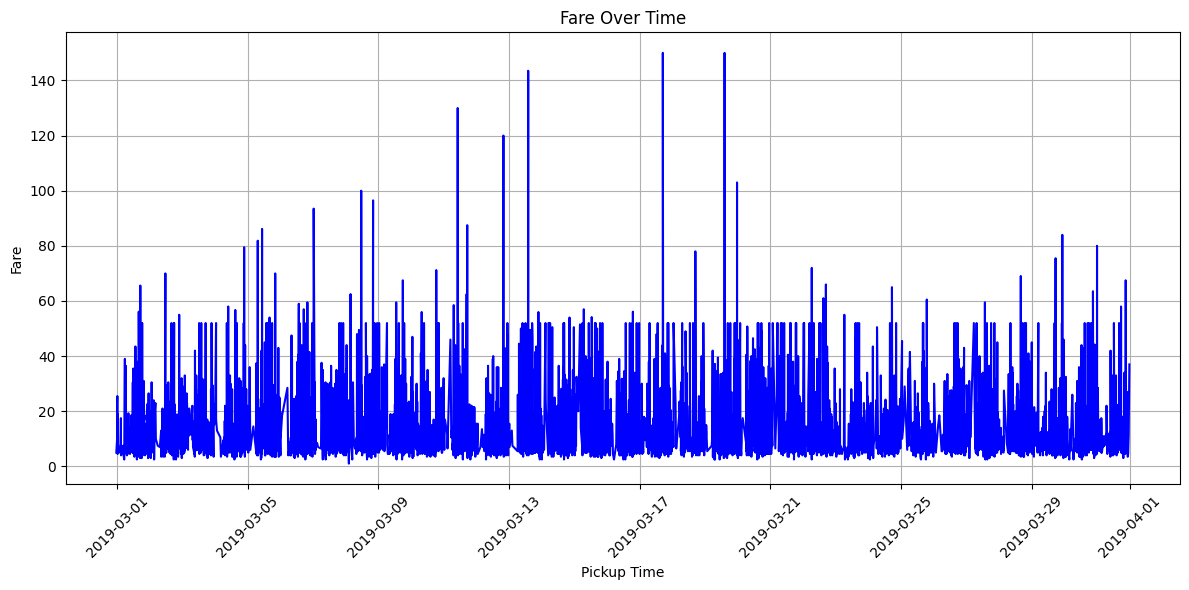

In [6]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = sns.load_dataset("taxis")

# Convert pickup column to datetime
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort by pickup time
df = df.sort_values('pickup')

# Plot line chart
plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'], color='blue')

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()



3.2. Bar Chart

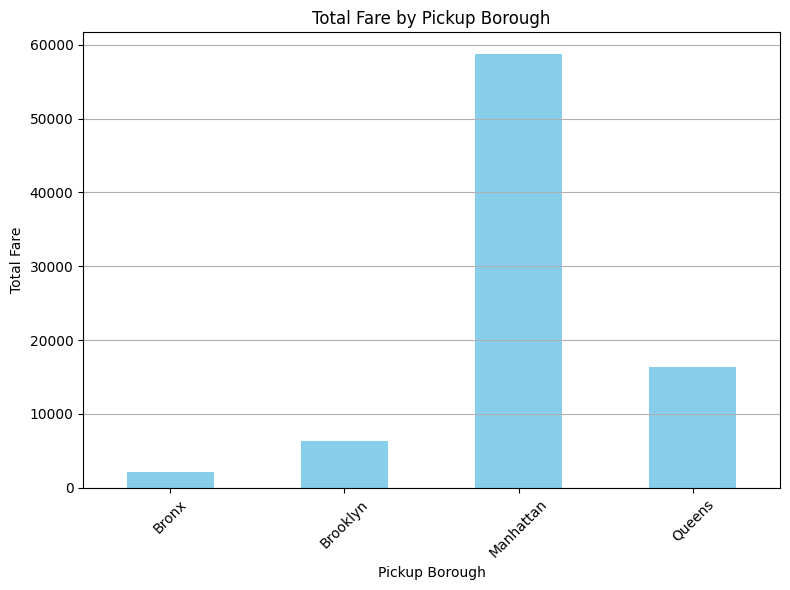

In [7]:
# Bar Chart
# Create a bar chart to show the total fare for each pickup_borough

# Group the data by pickup_borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Plot the bar chart
plt.figure(figsize=(8, 6))
borough_fare.plot(kind='bar', color='skyblue')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

3.3 Pie Chart

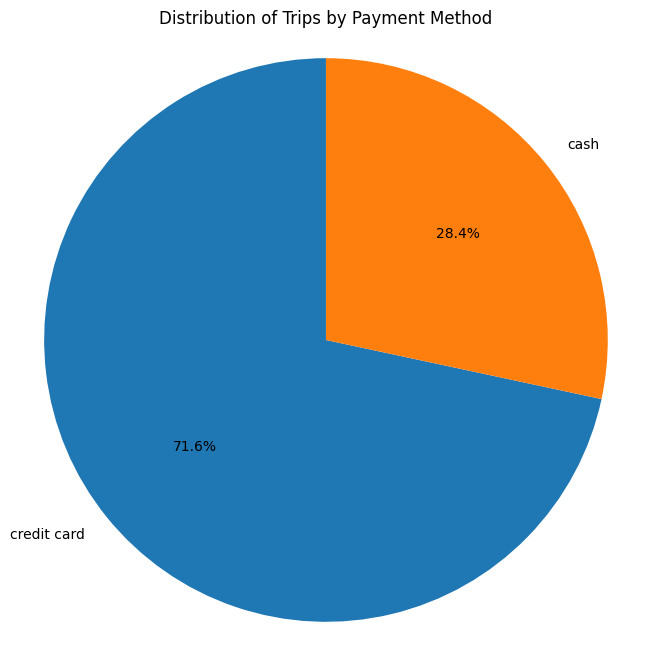

In [8]:
# Pie Chart
# Plot the distribution of trips based on payment method

# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.axis('equal')  # Makes the pie chart circular

plt.show()

3.4 Histogram

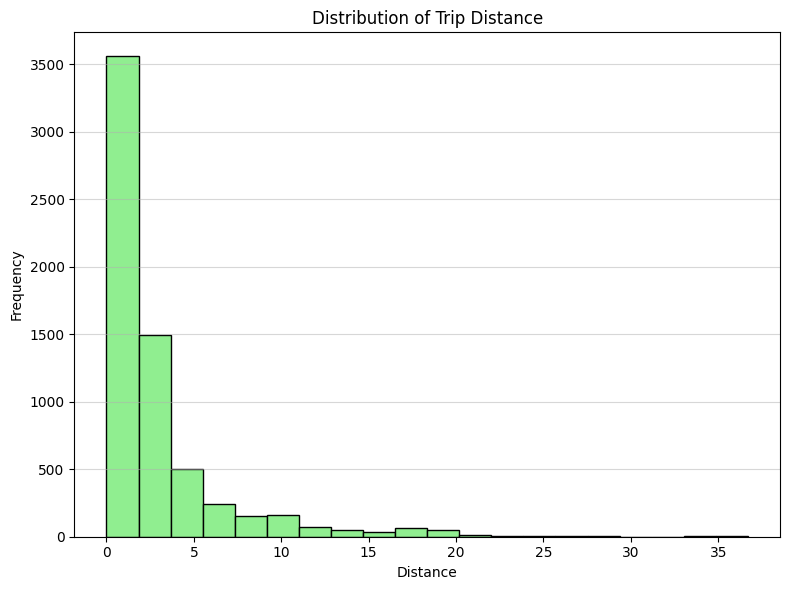

In [9]:
# Histogram
# Create a histogram to visualize the distribution of distance

plt.figure(figsize=(8, 6))

plt.hist(df['distance'], bins=20, color='lightgreen', edgecolor='black')

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.5)

plt.tight_layout()
plt.show()

3.5 Box Plot


<Figure size 1000x600 with 0 Axes>

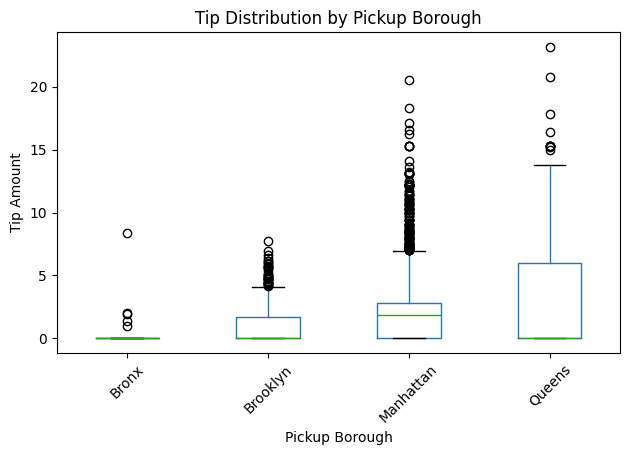

In [10]:
# Box Plot
# Visualize the distribution of tip amounts for each pickup_borough

plt.figure(figsize=(10, 6))

df.boxplot(
    column='tip',
    by='pickup_borough',
    grid=False
)

plt.title('Tip Distribution by Pickup Borough')
plt.suptitle('')  # Removes the default extra title
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4. Visualizations using Seaborn:

4.1 Count Plot

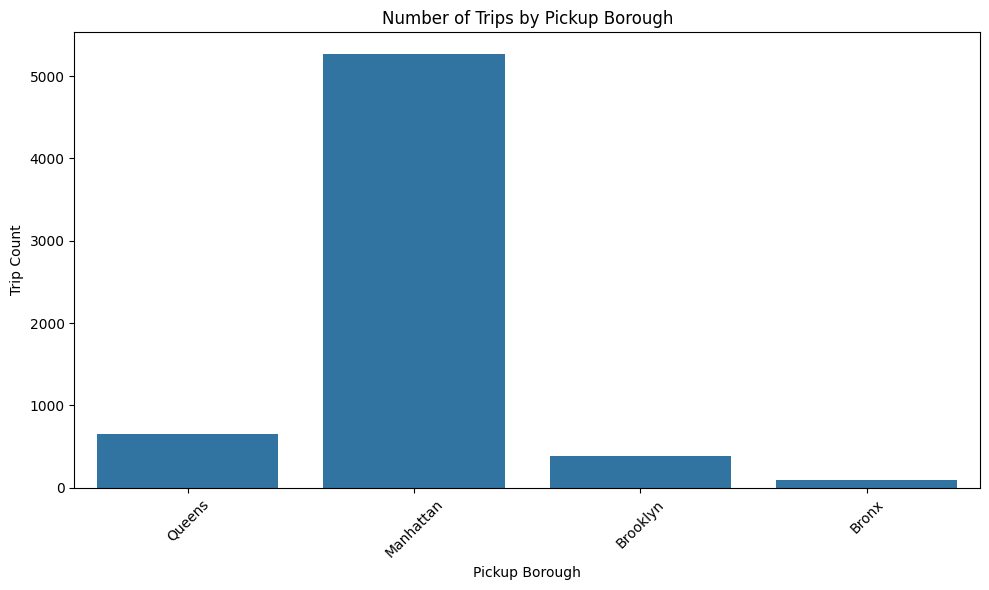

In [11]:
# Count Plot
# Visualize the number of trips in each pickup_borough

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Trip Count')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4.2 Scatter Plot

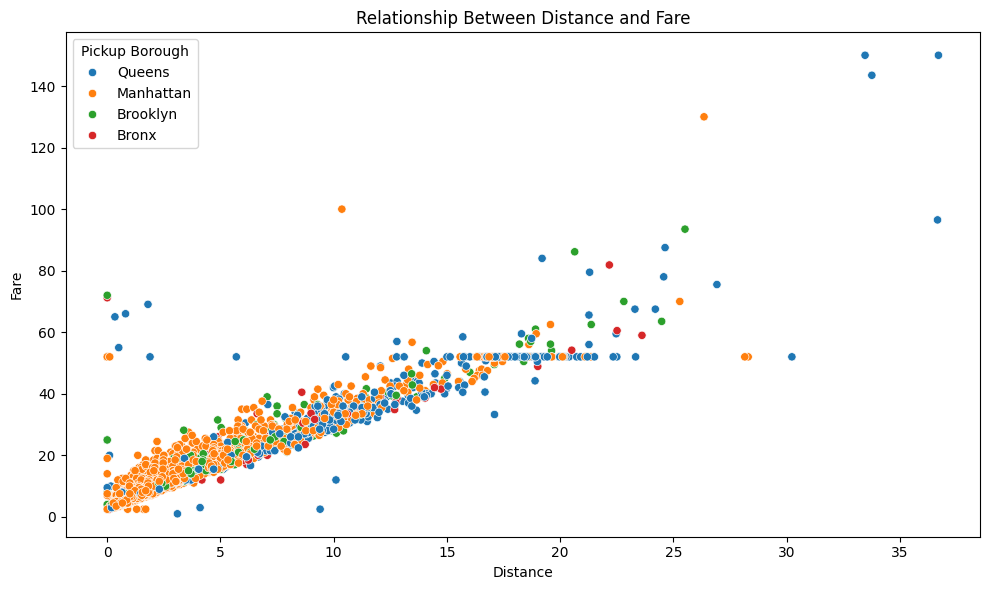

In [12]:
# Scatter Plot
# Show the relationship between distance and fare

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.legend(title='Pickup Borough')

plt.tight_layout()
plt.show()

4.3 Heat Map

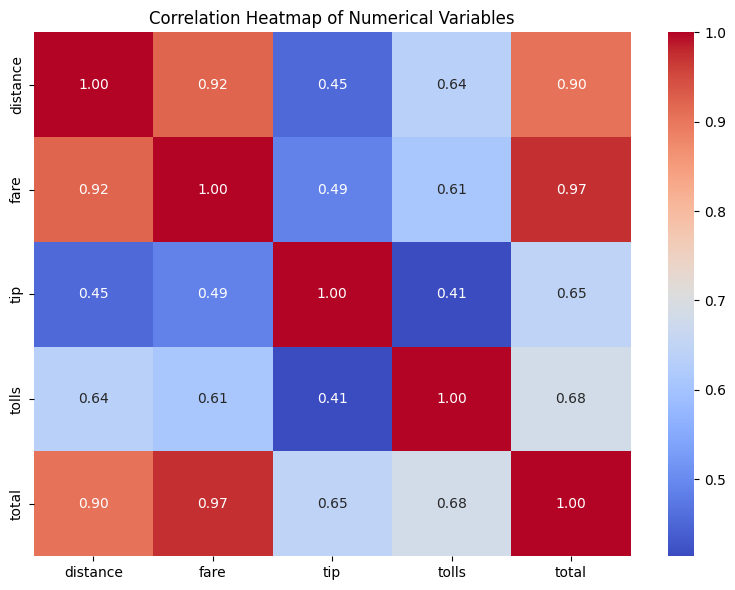

In [13]:
# Heatmap
# Visualize the correlation between numerical variables

# Select numerical columns
corr_matrix = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.tight_layout()
plt.show()

4.4 Pair Plot

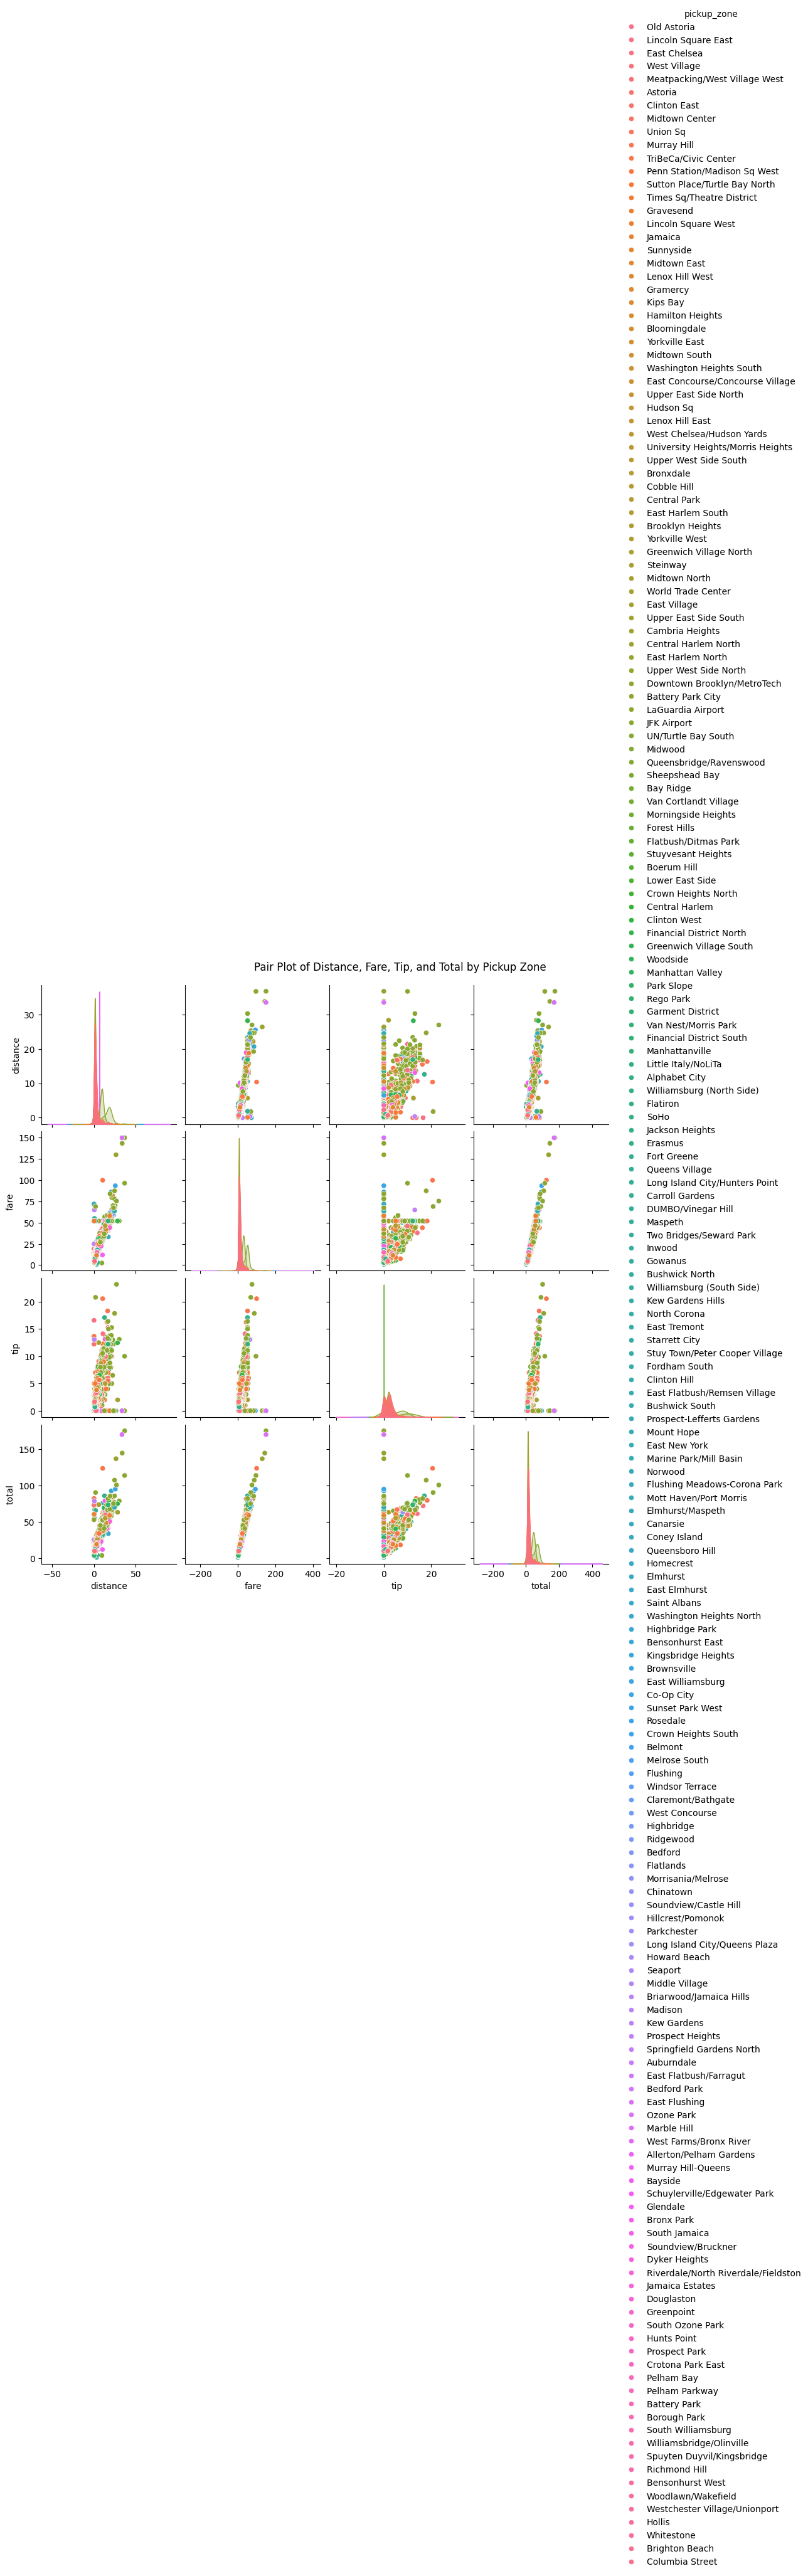

In [15]:
# Pair Plot
# Visualize pairwise relationships between distance, fare, tip, and total

sns.pairplot(
    df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.suptitle('Pair Plot of Distance, Fare, Tip, and Total by Pickup Zone', y=1.02)

plt.show()

4.5 Violin Plot

/tmp/ipykernel_859/951206550.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


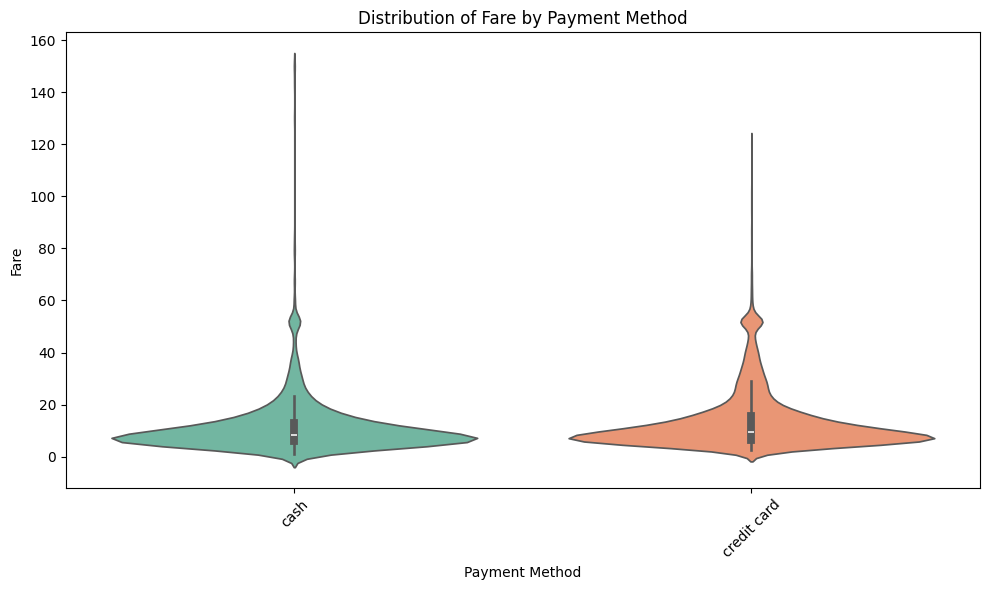

In [16]:
# Violin Plot
# Show the distribution of fare for each payment method

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    palette='Set2'
)

plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()